# به نام خدا

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
df = pd.read_csv("/home/amd/data-visualization/Lectures/06 Real-world Projects/datasets/housing.csv")

In [ ]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [ ]:
# Converting object to categorical
categorical_columns = set(df.columns) - {'price', 'area'}

for col in categorical_columns:
    df[col] = df[col].astype('category')

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   price             545 non-null    int64   
 1   area              545 non-null    int64   
 2   bedrooms          545 non-null    category
 3   bathrooms         545 non-null    category
 4   stories           545 non-null    category
 5   mainroad          545 non-null    category
 6   guestroom         545 non-null    category
 7   basement          545 non-null    category
 8   hotwaterheating   545 non-null    category
 9   airconditioning   545 non-null    category
 10  parking           545 non-null    category
 11  prefarea          545 non-null    category
 12  furnishingstatus  545 non-null    category
dtypes: category(11), int64(2)
memory usage: 16.2 KB


<div dir='rtl'>

ابتدای کار univariate analysis | تحلیل تک متغیره

In [31]:
df.price.min()

1750000

In [32]:
# اندازه داده ها رو ساده تر میکنیم
df['price'] = df['price'] / 1000000

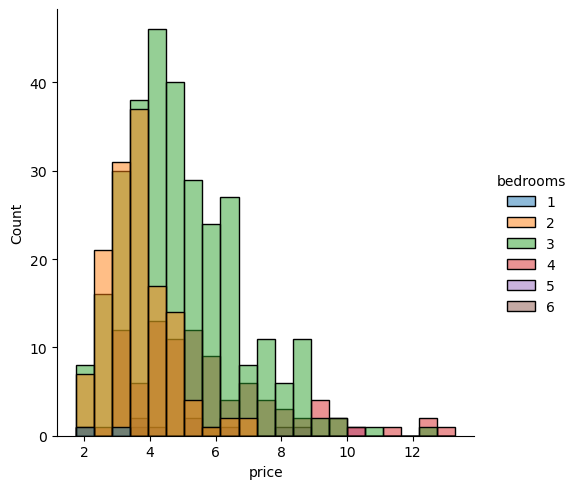

In [37]:
sns.displot(
    data=df,
    x='price',
    hue='bedrooms'
)

In [34]:
df.area.min()

1650

In [35]:
df['area'] = df['area'] / 1000

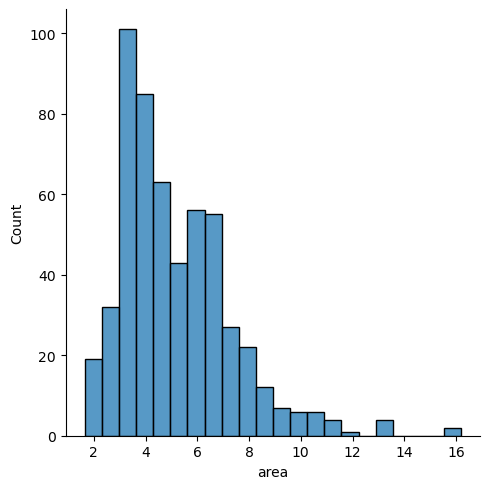

In [36]:
sns.displot(
    data=df,
    x='area'
)

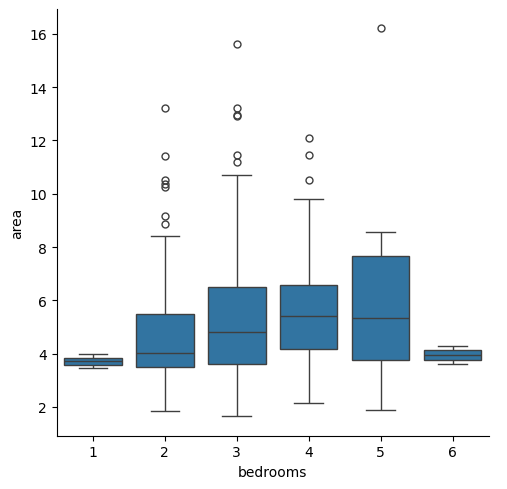

In [40]:
sns.catplot(
    data=df,
    x='bedrooms',
    y='area',
    kind='box'
)

<div dir='rtl'>

دومورد عجیب:
- خونه های یک اتاقه خیلی کمه
- خونه های 6 اتاقه مساحت خیلی کمی دارند

<Axes: xlabel='price', ylabel='area'>

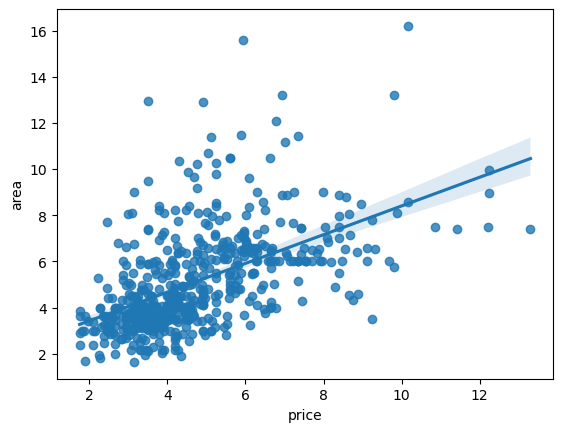

In [41]:
sns.regplot(
    data=df,
    x='price',
    y='area'
)

In [42]:
# ستون‌های دسته‌ای متنی را به عدد تبدیل می‌کنیم
for col in categorical_columns:
    df[col] = df[col].cat.codes

<Axes: >

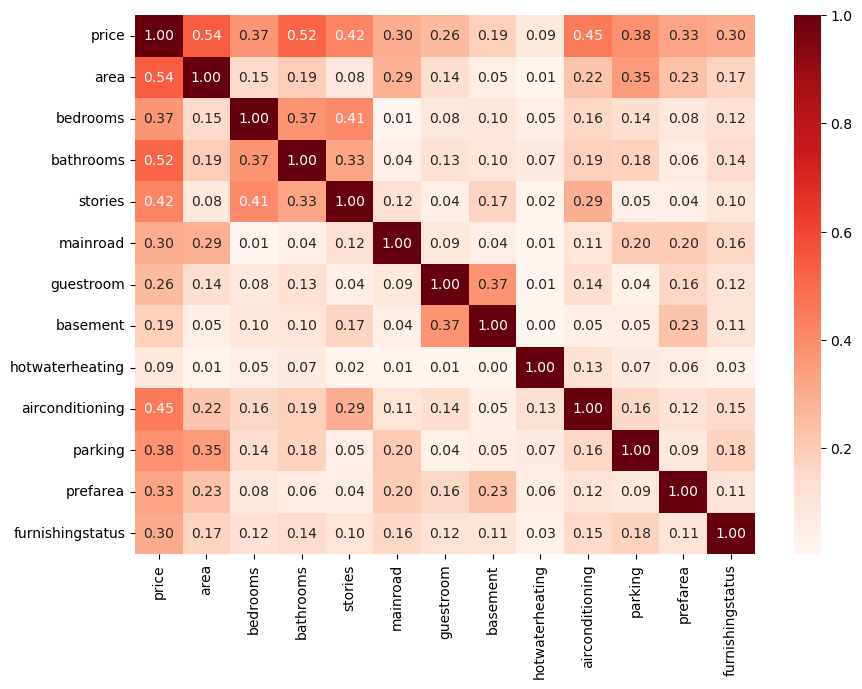

In [55]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    abs(df.corr()),
    annot=True,
    fmt='.2f',
    cmap='Reds'
)